100%|██████████| 68/68 [00:00<00:00, 439.88it/s]



Number of subjects in statistical tests: 68

Paired subject-level Wilcoxon signed-rank tests for MAE
Holm correction is applied separately within each BP metric.

SBP:
LS vs ML: mean paired MAE difference (LS - ML) = 5.55 mmHg, raw p < 0.001, Holm-adjusted p < 0.001, lower MAE: ML
LS vs Bayesian: mean paired MAE difference (LS - Bayesian) = 6.00 mmHg, raw p < 0.001, Holm-adjusted p < 0.001, lower MAE: Bayesian
ML vs Bayesian: mean paired MAE difference (ML - Bayesian) = 0.44 mmHg, raw p < 0.001, Holm-adjusted p < 0.001, lower MAE: Bayesian

DBP:
LS vs ML: mean paired MAE difference (LS - ML) = 3.73 mmHg, raw p < 0.001, Holm-adjusted p < 0.001, lower MAE: ML
LS vs Bayesian: mean paired MAE difference (LS - Bayesian) = 4.66 mmHg, raw p < 0.001, Holm-adjusted p < 0.001, lower MAE: Bayesian
ML vs Bayesian: mean paired MAE difference (ML - Bayesian) = 0.94 mmHg, raw p < 0.001, Holm-adjusted p < 0.001, lower MAE: Bayesian

MAP:
LS vs ML: mean paired MAE difference (LS - ML) = 0.17 mmHg, raw

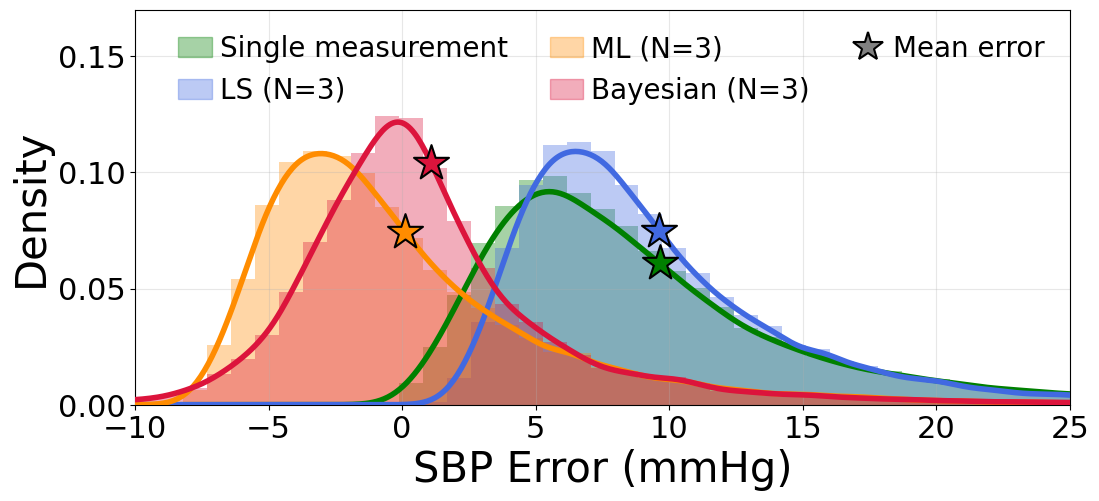

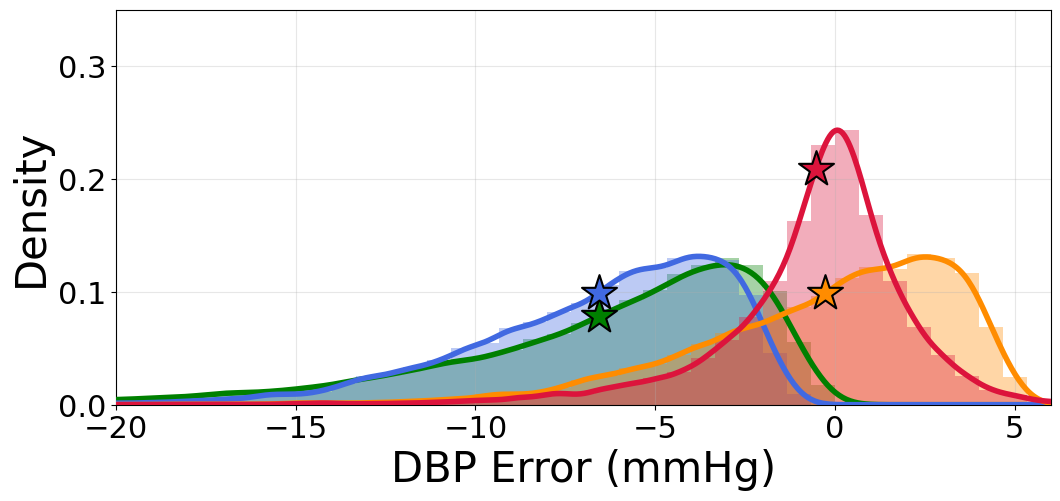

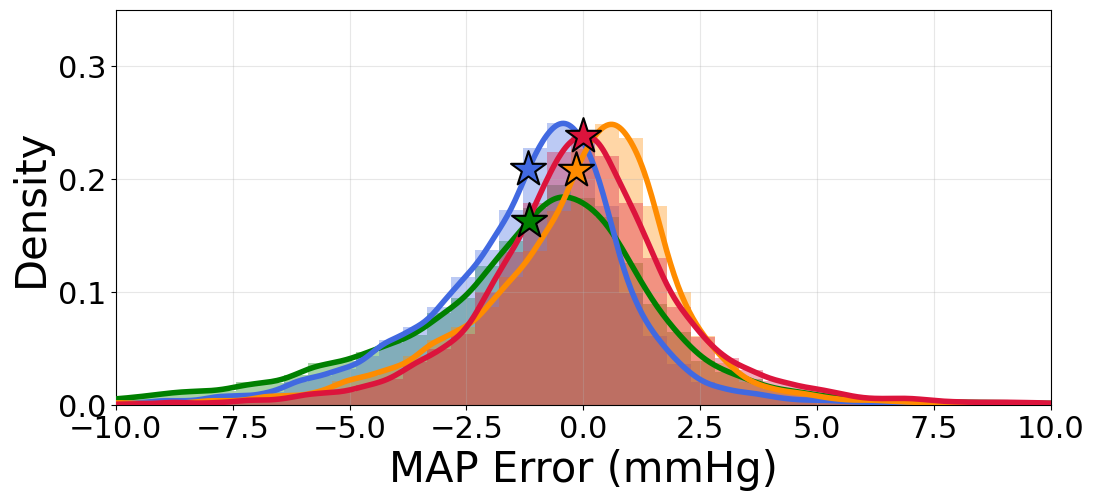

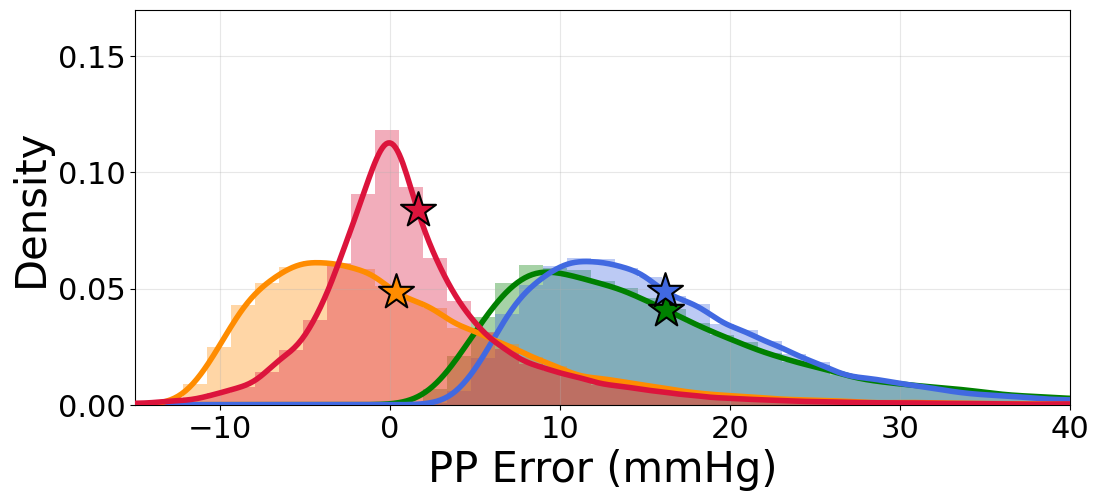

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde, wilcoxon
from tqdm import tqdm

N = 3                               # Number of observations
N_SAMPLES_PER_SUBJECT = 1000        # Number of samples in bootstrapping per subject
RANDOM_SEED = 0                     # Random seed for reproducibility

fig_dir = '../figures'
os.makedirs(fig_dir, exist_ok=True)
BP_dir = f'../results/bias_corrected_BP_N_{N}/2p0'
files = os.listdir(BP_dir)
files = [file for file in files if file.endswith('.npz') and file != 'mean_cov.npz']

err_sbp_sing, err_sbp_ls, err_sbp_ml, err_sbp_bayes = [], [], [], []
err_dbp_sing, err_dbp_ls, err_dbp_ml, err_dbp_bayes = [], [], [], []
err_map_sing, err_map_ls, err_map_ml, err_map_bayes = [], [], [], []
err_pup_sing, err_pup_ls, err_pup_ml, err_pup_bayes = [], [], [], []

for file in tqdm(files):
    path = f'{BP_dir}/{file}'
    data = np.load(path)

    sbp_sing = data['sbp_sing']
    sbp_ls = data['sbp_ls']
    sbp_ml = data['sbp_ml']
    sbp_bayes = data['sbp_bayes']
    sbp_tru_sing = data['sbp_tru_sing']
    sbp_tru_mult = data['sbp_tru_mult']

    dbp_sing = data['dbp_sing']
    dbp_ls = data['dbp_ls']
    dbp_ml = data['dbp_ml']
    dbp_bayes = data['dbp_bayes']
    dbp_tru_sing = data['dbp_tru_sing']
    dbp_tru_mult = data['dbp_tru_mult']

    map_sing = data['map_sing']
    map_ls = data['map_ls']
    map_ml = data['map_ml']
    map_bayes = data['map_bayes']
    map_tru_sing = data['map_tru_sing']
    map_tru_mult = data['map_tru_mult']

    pup_sing = data['pup_sing']
    pup_ls = data['pup_ls']
    pup_ml = data['pup_ml']
    pup_bayes = data['pup_bayes']
    pup_tru_sing = data['pup_tru_sing']
    pup_tru_mult = data['pup_tru_mult']

    err_sbp_sing.append(sbp_tru_sing - sbp_sing)
    err_sbp_ls.append(sbp_tru_mult - sbp_ls)
    err_sbp_ml.append(sbp_tru_mult - sbp_ml)
    err_sbp_bayes.append(sbp_tru_mult - sbp_bayes)

    err_dbp_sing.append(dbp_tru_sing - dbp_sing)
    err_dbp_ls.append(dbp_tru_mult - dbp_ls)
    err_dbp_ml.append(dbp_tru_mult - dbp_ml)
    err_dbp_bayes.append(dbp_tru_mult - dbp_bayes)

    err_map_sing.append(map_tru_sing - map_sing)
    err_map_ls.append(map_tru_mult - map_ls)
    err_map_ml.append(map_tru_mult - map_ml)
    err_map_bayes.append(map_tru_mult - map_bayes)

    err_pup_sing.append(pup_tru_sing - pup_sing)
    err_pup_ls.append(pup_tru_mult - pup_ls)
    err_pup_ml.append(pup_tru_mult - pup_ml)
    err_pup_bayes.append(pup_tru_mult - pup_bayes)

#%%
# =========================================================
# Paired subject-level statistical comparisons of MAE
# Keep this section BEFORE subject resampling.
# Each subject contributes one MAE value to the statistical test.
# =========================================================

def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    running_max = 0.0
    m = len(p_values)

    for rank, index in enumerate(order):
        corrected_p = (m - rank) * p_values[index]
        running_max = max(running_max, corrected_p)
        adjusted[index] = min(running_max, 1.0)

    return adjusted


def format_p_value(p_value):
    if p_value < 0.001:
        return '< 0.001'
    return f'= {p_value:.3f}'


def compare_methods_subject_level(error_lists, method_names):
    subject_mae = {
        method: np.array([np.mean(np.abs(subject_error)) for subject_error in errors])
        for method, errors in zip(method_names, error_lists)
    }

    comparisons = []
    raw_p_values = []

    for i in range(len(method_names)):
        for j in range(i + 1, len(method_names)):
            method_1 = method_names[i]
            method_2 = method_names[j]

            paired_difference = subject_mae[method_1] - subject_mae[method_2]
            mean_difference = np.mean(paired_difference)

            if np.allclose(paired_difference, 0):
                p_value = 1.0
            else:
                _, p_value = wilcoxon(paired_difference, alternative='two-sided', method='auto')

            comparisons.append((method_1, method_2, mean_difference, p_value))
            raw_p_values.append(p_value)

    adjusted_p_values = holm_adjust(raw_p_values)

    for (method_1, method_2, mean_difference, p_value), p_value_holm in zip(comparisons, adjusted_p_values):
        if mean_difference < 0:
            lower_mae_method = method_1
        elif mean_difference > 0:
            lower_mae_method = method_2
        else:
            lower_mae_method = 'Equal'

        print(
            f'{method_1} vs {method_2}: '
            f'mean paired MAE difference ({method_1} - {method_2}) = {mean_difference:.2f} mmHg, '
            f'raw p {format_p_value(p_value)}, '
            f'Holm-adjusted p {format_p_value(p_value_holm)}, '
            f'lower MAE: {lower_mae_method}'
        )


method_names = ['LS', 'ML', 'Bayesian']

print(f'\nNumber of subjects in statistical tests: {len(err_sbp_ls)}')

if len(err_sbp_ls) != 68:
    raise ValueError('Expected 68 subjects. Do not continue until this is resolved.')

print('\nPaired subject-level Wilcoxon signed-rank tests for MAE')
print('Holm correction is applied separately within each BP metric.')

print('\nSBP:')
compare_methods_subject_level([err_sbp_ls, err_sbp_ml, err_sbp_bayes], method_names)

print('\nDBP:')
compare_methods_subject_level([err_dbp_ls, err_dbp_ml, err_dbp_bayes], method_names)

print('\nMAP:')
compare_methods_subject_level([err_map_ls, err_map_ml, err_map_bayes], method_names)

print('\nPP:')
compare_methods_subject_level([err_pup_ls, err_pup_ml, err_pup_bayes], method_names)

#%%
# =========================================================
# Randomly sample the same number of observations per subject
# =========================================================
#
# Every subject contributes exactly N_SAMPLES_PER_SUBJECT observations.
# Sampling is performed with replacement.
#
# Corresponding variables use the same randomly selected indices so that
# pairing between SBP/DBP/MAP/PP and between LS/ML/Bayesian is preserved.
# =========================================================

rng = np.random.default_rng(RANDOM_SEED)


def resample_subject_group(error_lists, n_samples):
    n_subjects = len(error_lists[0])
    resampled = [[] for _ in error_lists]

    for subject_idx in range(n_subjects):
        n_available = len(error_lists[0][subject_idx])

        if n_available == 0:
            raise ValueError(f'Subject {subject_idx} has no available observations.')

        for errors in error_lists:
            if len(errors[subject_idx]) != n_available:
                raise ValueError(f'Corresponding arrays have different lengths for subject {subject_idx}.')

        indices = rng.choice(n_available, size=n_samples, replace=True)

        for array_idx, errors in enumerate(error_lists):
            resampled[array_idx].append(np.asarray(errors[subject_idx])[indices])

    return [np.concatenate(x) for x in resampled]


# Single-measurement errors
# Use identical indices for SBP, DBP, MAP, and PP.
(
    err_sbp_sing,
    err_dbp_sing,
    err_map_sing,
    err_pup_sing
) = resample_subject_group(
    [
        err_sbp_sing,
        err_dbp_sing,
        err_map_sing,
        err_pup_sing
    ],
    N_SAMPLES_PER_SUBJECT
)


# Multi-measurement errors
# Use identical indices across BP metrics and estimators.
(
    err_sbp_ls,
    err_sbp_ml,
    err_sbp_bayes,
    err_dbp_ls,
    err_dbp_ml,
    err_dbp_bayes,
    err_map_ls,
    err_map_ml,
    err_map_bayes,
    err_pup_ls,
    err_pup_ml,
    err_pup_bayes
) = resample_subject_group(
    [
        err_sbp_ls,
        err_sbp_ml,
        err_sbp_bayes,
        err_dbp_ls,
        err_dbp_ml,
        err_dbp_bayes,
        err_map_ls,
        err_map_ml,
        err_map_bayes,
        err_pup_ls,
        err_pup_ml,
        err_pup_bayes
    ],
    N_SAMPLES_PER_SUBJECT
)

print('\nEqual subject sampling:')
print(f'Number of subjects: {len(files)}')
print(f'Number of sampled observations per subject: {N_SAMPLES_PER_SUBJECT}')
print(f'Total observations per pooled distribution: {len(err_sbp_ls)}')

#%%
# =========================================================
# Mean absolute error and STD of absolute error
# =========================================================

print('\nMean Absolute Error ± STD of Absolute Error:')

print(f'SBP error (single): {np.mean(np.abs(err_sbp_sing)):.1f} ± {np.std(np.abs(err_sbp_sing)):.1f}')
print(f'DBP error (single): {np.mean(np.abs(err_dbp_sing)):.1f} ± {np.std(np.abs(err_dbp_sing)):.1f}')
print(f'SBP error (LS N={N}): {np.mean(np.abs(err_sbp_ls)):.1f} ± {np.std(np.abs(err_sbp_ls)):.1f}')
print(f'DBP error (LS N={N}): {np.mean(np.abs(err_dbp_ls)):.1f} ± {np.std(np.abs(err_dbp_ls)):.1f}')
print(f'SBP error (ML N={N}): {np.mean(np.abs(err_sbp_ml)):.1f} ± {np.std(np.abs(err_sbp_ml)):.1f}')
print(f'DBP error (ML N={N}): {np.mean(np.abs(err_dbp_ml)):.1f} ± {np.std(np.abs(err_dbp_ml)):.1f}')
print(f'SBP error (Bayes N={N}): {np.mean(np.abs(err_sbp_bayes)):.1f} ± {np.std(np.abs(err_sbp_bayes)):.1f}')
print(f'DBP error (Bayes N={N}): {np.mean(np.abs(err_dbp_bayes)):.1f} ± {np.std(np.abs(err_dbp_bayes)):.1f}')

print('_' * 40)

print(f'MAP error (single): {np.mean(np.abs(err_map_sing)):.1f} ± {np.std(np.abs(err_map_sing)):.1f}')
print(f'MAP error (LS N={N}): {np.mean(np.abs(err_map_ls)):.1f} ± {np.std(np.abs(err_map_ls)):.1f}')
print(f'MAP error (ML N={N}): {np.mean(np.abs(err_map_ml)):.1f} ± {np.std(np.abs(err_map_ml)):.1f}')
print(f'MAP error (Bayes N={N}): {np.mean(np.abs(err_map_bayes)):.1f} ± {np.std(np.abs(err_map_bayes)):.1f}')

print('_' * 40)

print(f'PP error (single): {np.mean(np.abs(err_pup_sing)):.1f} ± {np.std(np.abs(err_pup_sing)):.1f}')
print(f'PP error (LS N={N}): {np.mean(np.abs(err_pup_ls)):.1f} ± {np.std(np.abs(err_pup_ls)):.1f}')
print(f'PP error (ML N={N}): {np.mean(np.abs(err_pup_ml)):.1f} ± {np.std(np.abs(err_pup_ml)):.1f}')
print(f'PP error (Bayes N={N}): {np.mean(np.abs(err_pup_bayes)):.1f} ± {np.std(np.abs(err_pup_bayes)):.1f}')

print('_' * 40)

# =========================================================
# Mean error and STD of error
# =========================================================

print('\nError ± STD of Error:')

print(f'SBP error (single): {np.mean(err_sbp_sing):.1f} ± {np.std(err_sbp_sing):.1f}')
print(f'DBP error (single): {np.mean(err_dbp_sing):.1f} ± {np.std(err_dbp_sing):.1f}')
print(f'SBP error (LS N={N}): {np.mean(err_sbp_ls):.1f} ± {np.std(err_sbp_ls):.1f}')
print(f'DBP error (LS N={N}): {np.mean(err_dbp_ls):.1f} ± {np.std(err_dbp_ls):.1f}')
print(f'SBP error (ML N={N}): {np.mean(err_sbp_ml):.1f} ± {np.std(err_sbp_ml):.1f}')
print(f'DBP error (ML N={N}): {np.mean(err_dbp_ml):.1f} ± {np.std(err_dbp_ml):.1f}')
print(f'SBP error (Bayes N={N}): {np.mean(err_sbp_bayes):.1f} ± {np.std(err_sbp_bayes):.1f}')
print(f'DBP error (Bayes N={N}): {np.mean(err_dbp_bayes):.1f} ± {np.std(err_dbp_bayes):.1f}')

print('_' * 40)

print(f'MAP error (single): {np.mean(err_map_sing):.1f} ± {np.std(err_map_sing):.1f}')
print(f'MAP error (LS N={N}): {np.mean(err_map_ls):.1f} ± {np.std(err_map_ls):.1f}')
print(f'MAP error (ML N={N}): {np.mean(err_map_ml):.1f} ± {np.std(err_map_ml):.1f}')
print(f'MAP error (Bayes N={N}): {np.mean(err_map_bayes):.1f} ± {np.std(err_map_bayes):.1f}')

print('_' * 40)

print(f'PP error (single): {np.mean(err_pup_sing):.1f} ± {np.std(err_pup_sing):.1f}')
print(f'PP error (LS N={N}): {np.mean(err_pup_ls):.1f} ± {np.std(err_pup_ls):.1f}')
print(f'PP error (ML N={N}): {np.mean(err_pup_ml):.1f} ± {np.std(err_pup_ml):.1f}')
print(f'PP error (Bayes N={N}): {np.mean(err_pup_bayes):.1f} ± {np.std(err_pup_bayes):.1f}')

print('_' * 40)


print('\n95% interval [2.5th, 97.5th percentile]:')

print('\nSBP:')
print(f'Single - Error: [{np.percentile(err_sbp_sing, 2.5):.1f}, {np.percentile(err_sbp_sing, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_sbp_sing), 2.5):.1f}, {np.percentile(np.abs(err_sbp_sing), 97.5):.1f}]')
print(f'LS N={N} - Error: [{np.percentile(err_sbp_ls, 2.5):.1f}, {np.percentile(err_sbp_ls, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_sbp_ls), 2.5):.1f}, {np.percentile(np.abs(err_sbp_ls), 97.5):.1f}]')
print(f'ML N={N} - Error: [{np.percentile(err_sbp_ml, 2.5):.1f}, {np.percentile(err_sbp_ml, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_sbp_ml), 2.5):.1f}, {np.percentile(np.abs(err_sbp_ml), 97.5):.1f}]')
print(f'Bayes N={N} - Error: [{np.percentile(err_sbp_bayes, 2.5):.1f}, {np.percentile(err_sbp_bayes, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_sbp_bayes), 2.5):.1f}, {np.percentile(np.abs(err_sbp_bayes), 97.5):.1f}]')

print('\nDBP:')
print(f'Single - Error: [{np.percentile(err_dbp_sing, 2.5):.1f}, {np.percentile(err_dbp_sing, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_dbp_sing), 2.5):.1f}, {np.percentile(np.abs(err_dbp_sing), 97.5):.1f}]')
print(f'LS N={N} - Error: [{np.percentile(err_dbp_ls, 2.5):.1f}, {np.percentile(err_dbp_ls, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_dbp_ls), 2.5):.1f}, {np.percentile(np.abs(err_dbp_ls), 97.5):.1f}]')
print(f'ML N={N} - Error: [{np.percentile(err_dbp_ml, 2.5):.1f}, {np.percentile(err_dbp_ml, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_dbp_ml), 2.5):.1f}, {np.percentile(np.abs(err_dbp_ml), 97.5):.1f}]')
print(f'Bayes N={N} - Error: [{np.percentile(err_dbp_bayes, 2.5):.1f}, {np.percentile(err_dbp_bayes, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_dbp_bayes), 2.5):.1f}, {np.percentile(np.abs(err_dbp_bayes), 97.5):.1f}]')

print('\nMAP:')
print(f'Single - Error: [{np.percentile(err_map_sing, 2.5):.1f}, {np.percentile(err_map_sing, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_map_sing), 2.5):.1f}, {np.percentile(np.abs(err_map_sing), 97.5):.1f}]')
print(f'LS N={N} - Error: [{np.percentile(err_map_ls, 2.5):.1f}, {np.percentile(err_map_ls, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_map_ls), 2.5):.1f}, {np.percentile(np.abs(err_map_ls), 97.5):.1f}]')
print(f'ML N={N} - Error: [{np.percentile(err_map_ml, 2.5):.1f}, {np.percentile(err_map_ml, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_map_ml), 2.5):.1f}, {np.percentile(np.abs(err_map_ml), 97.5):.1f}]')
print(f'Bayes N={N} - Error: [{np.percentile(err_map_bayes, 2.5):.1f}, {np.percentile(err_map_bayes, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_map_bayes), 2.5):.1f}, {np.percentile(np.abs(err_map_bayes), 97.5):.1f}]')

print('\nPP:')
print(f'Single - Error: [{np.percentile(err_pup_sing, 2.5):.1f}, {np.percentile(err_pup_sing, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_pup_sing), 2.5):.1f}, {np.percentile(np.abs(err_pup_sing), 97.5):.1f}]')
print(f'LS N={N} - Error: [{np.percentile(err_pup_ls, 2.5):.1f}, {np.percentile(err_pup_ls, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_pup_ls), 2.5):.1f}, {np.percentile(np.abs(err_pup_ls), 97.5):.1f}]')
print(f'ML N={N} - Error: [{np.percentile(err_pup_ml, 2.5):.1f}, {np.percentile(err_pup_ml, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_pup_ml), 2.5):.1f}, {np.percentile(np.abs(err_pup_ml), 97.5):.1f}]')
print(f'Bayes N={N} - Error: [{np.percentile(err_pup_bayes, 2.5):.1f}, {np.percentile(err_pup_bayes, 97.5):.1f}], Absolute Error: [{np.percentile(np.abs(err_pup_bayes), 2.5):.1f}, {np.percentile(np.abs(err_pup_bayes), 97.5):.1f}]')

#%%
color_single = 'green'
color_ls = 'royalblue'
color_ml = 'darkorange'
color_bayes = 'crimson'
star_size = 700
kde_lw = 4
hist_alpha = 0.35

def plot_kde(ax, data, x_grid, color):
    kde = gaussian_kde(data)
    ax.plot(x_grid, kde(x_grid), color=color, linewidth=kde_lw, zorder=8)
    return kde

# =========================================================
# SBP FIGURE
# =========================================================
fig, ax = plt.subplots(figsize=(11, 5))
bins_sbp = np.linspace(-10, 25, 40)

# ---------------- Histograms ----------------
ax.hist(err_sbp_sing, bins=bins_sbp, density=True, alpha=hist_alpha, color=color_single)
ax.hist(err_sbp_ls, bins=bins_sbp, density=True, alpha=hist_alpha, color=color_ls)
ax.hist(err_sbp_ml, bins=bins_sbp, density=True, alpha=hist_alpha, color=color_ml)
ax.hist(err_sbp_bayes, bins=bins_sbp, density=True, alpha=hist_alpha, color=color_bayes)

# ---------------- KDE curves ----------------
x_sbp = np.linspace(-10, 25, 500)
kde_single_sbp = plot_kde(ax, err_sbp_sing, x_sbp, color_single)
kde_ls_sbp = plot_kde(ax, err_sbp_ls, x_sbp, color_ls)
kde_ml_sbp = plot_kde(ax, err_sbp_ml, x_sbp, color_ml)
kde_bayes_sbp = plot_kde(ax, err_sbp_bayes, x_sbp, color_bayes)

# ---------------- Mean stars ----------------
mean_single_sbp = np.mean(err_sbp_sing)
mean_ls_sbp = np.mean(err_sbp_ls)
mean_ml_sbp = np.mean(err_sbp_ml)
mean_bayes_sbp = np.mean(err_sbp_bayes)

y_single_sbp = kde_single_sbp(mean_single_sbp)[0]
y_ls_sbp = kde_ls_sbp(mean_ls_sbp)[0]
y_ml_sbp = kde_ml_sbp(mean_ml_sbp)[0]
y_bayes_sbp = kde_bayes_sbp(mean_bayes_sbp)[0]

ax.scatter(mean_single_sbp, y_single_sbp, marker='*', s=star_size, color=color_single, edgecolors='black', linewidths=1.5, zorder=10)
ax.scatter(mean_ls_sbp, y_ls_sbp, marker='*', s=star_size, color=color_ls, edgecolors='black', linewidths=1.5, zorder=10)
ax.scatter(mean_ml_sbp, y_ml_sbp, marker='*', s=star_size, color=color_ml, edgecolors='black', linewidths=1.5, zorder=10)
ax.scatter(mean_bayes_sbp, y_bayes_sbp, marker='*', s=star_size, color=color_bayes, edgecolors='black', linewidths=1.5, zorder=10)
ax.set_xlabel('SBP Error (mmHg)', fontsize=30)
ax.set_ylabel('Density', fontsize=30)
ax.set_xlim(-10, 25)
ax.set_ylim(0, 0.17)
ax.tick_params(axis='x', labelsize=22)
ax.tick_params(axis='y', labelsize=22)
ax.grid(True, alpha=0.3)

# ---------------- Legend ----------------
# =========================================================
# Legend handles and labels
# =========================================================
hist_single = plt.Rectangle((0, 0), 1, 1, color=color_single, alpha=hist_alpha)
hist_ls = plt.Rectangle((0, 0), 1, 1, color=color_ls, alpha=hist_alpha)
hist_ml = plt.Rectangle((0, 0), 1, 1, color=color_ml, alpha=hist_alpha)
hist_bayes = plt.Rectangle((0, 0), 1, 1, color=color_bayes, alpha=hist_alpha)
mean_handle = plt.Line2D([0], [0], marker='*', color='none', markerfacecolor='gray', markeredgecolor='black', markeredgewidth=1.5, markersize=22)

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=color_single, alpha=hist_alpha),
    plt.Rectangle((0, 0), 1, 1, color=color_ls, alpha=hist_alpha),
    plt.Rectangle((0, 0), 1, 1, color=color_ml, alpha=hist_alpha),
    plt.Rectangle((0, 0), 1, 1, color=color_bayes, alpha=hist_alpha),
    plt.Line2D([0], [0], marker='*', color='none', markerfacecolor='gray', markeredgecolor='black', markeredgewidth=1.5, markersize=22)
]

legend_labels = ['Single measurement', f'LS (N={N})', f'ML (N={N})', f'Bayesian (N={N})', 'Mean error']
ax.legend(legend_handles, legend_labels, fontsize=20, loc='upper right', frameon=False, ncol=3, columnspacing=1.5, labelspacing=0.5, handletextpad=0.3, handlelength=1.2)

fig.subplots_adjust(left=0.12, right=0.97, bottom=0.18, top=0.97)
fig_path = f'{fig_dir}/pdf_sbp.png'
plt.savefig(fig_path, dpi=300)
plt.show()
plt.close()


# =========================================================
# DBP FIGURE
# =========================================================
fig, ax = plt.subplots(figsize=(11, 5))
bins_dbp = np.linspace(-20, 6, 40)

# ---------------- Histograms ----------------
ax.hist(err_dbp_sing, bins=bins_dbp, density=True, alpha=hist_alpha, color=color_single)
ax.hist(err_dbp_ls, bins=bins_dbp, density=True, alpha=hist_alpha, color=color_ls)
ax.hist(err_dbp_ml, bins=bins_dbp, density=True, alpha=hist_alpha, color=color_ml)
ax.hist(err_dbp_bayes, bins=bins_dbp, density=True, alpha=hist_alpha, color=color_bayes)

# ---------------- KDE curves ----------------
x_dbp = np.linspace(-20, 6, 500)
kde_single_dbp = plot_kde(ax, err_dbp_sing, x_dbp, color_single)
kde_ls_dbp = plot_kde(ax, err_dbp_ls, x_dbp, color_ls)
kde_ml_dbp = plot_kde(ax, err_dbp_ml, x_dbp, color_ml)
kde_bayes_dbp = plot_kde(ax, err_dbp_bayes, x_dbp, color_bayes)

# ---------------- Mean stars ----------------
mean_single_dbp = np.mean(err_dbp_sing)
mean_ls_dbp = np.mean(err_dbp_ls)
mean_ml_dbp = np.mean(err_dbp_ml)
mean_bayes_dbp = np.mean(err_dbp_bayes)

y_single_dbp = kde_single_dbp(mean_single_dbp)[0]
y_ls_dbp = kde_ls_dbp(mean_ls_dbp)[0]
y_ml_dbp = kde_ml_dbp(mean_ml_dbp)[0]
y_bayes_dbp = kde_bayes_dbp(mean_bayes_dbp)[0]

ax.scatter(mean_single_dbp, y_single_dbp, marker='*', s=star_size, color=color_single, edgecolors='black', linewidths=1.5, zorder=10)
ax.scatter(mean_ls_dbp, y_ls_dbp, marker='*', s=star_size, color=color_ls, edgecolors='black', linewidths=1.5, zorder=10)
ax.scatter(mean_ml_dbp, y_ml_dbp, marker='*', s=star_size, color=color_ml, edgecolors='black', linewidths=1.5, zorder=10)
ax.scatter(mean_bayes_dbp, y_bayes_dbp, marker='*', s=star_size, color=color_bayes, edgecolors='black', linewidths=1.5, zorder=10)
ax.set_xlabel('DBP Error (mmHg)', fontsize=30)
ax.set_ylabel('Density', fontsize=30)
ax.set_xlim(-20, 6)
ax.set_ylim(0, 0.35)
ax.tick_params(axis='x', labelsize=22)
ax.set_yticks(np.arange(0, 0.31, 0.1))
ax.tick_params(axis='y', labelsize=22)
ax.grid(True, alpha=0.3)
fig.subplots_adjust(left=0.12, right=0.97, bottom=0.18, top=0.97)

fig_path = f'{fig_dir}/pdf_dbp.png'
plt.savefig(fig_path, dpi=300)
plt.show()
plt.close()

# =========================================================
# MAP FIGURE
# =========================================================
fig, ax = plt.subplots(figsize=(11, 5))
bins_map = np.linspace(-10, 10, 40)

# ---------------- Histograms ----------------
ax.hist(err_map_sing, bins=bins_map, density=True, alpha=hist_alpha, color=color_single)
ax.hist(err_map_ls, bins=bins_map, density=True, alpha=hist_alpha, color=color_ls)
ax.hist(err_map_ml, bins=bins_map, density=True, alpha=hist_alpha, color=color_ml)
ax.hist(err_map_bayes, bins=bins_map, density=True, alpha=hist_alpha, color=color_bayes)

# ---------------- KDE curves ----------------
x_map = np.linspace(-10, 10, 500)
kde_single_map = plot_kde(ax, err_map_sing, x_map, color_single)
kde_ls_map = plot_kde(ax, err_map_ls, x_map, color_ls)
kde_ml_map = plot_kde(ax, err_map_ml, x_map, color_ml)
kde_bayes_map = plot_kde(ax, err_map_bayes, x_map, color_bayes)

# ---------------- Mean stars ----------------
mean_single_map = np.mean(err_map_sing)
mean_ls_map = np.mean(err_map_ls)
mean_ml_map = np.mean(err_map_ml)
mean_bayes_map = np.mean(err_map_bayes)

y_single_map = kde_single_map(mean_single_map)[0]
y_ls_map = kde_ls_map(mean_ls_map)[0]
y_ml_map = kde_ml_map(mean_ml_map)[0]
y_bayes_map = kde_bayes_map(mean_bayes_map)[0]

ax.scatter(mean_single_map, y_single_map, marker='*', s=star_size, color=color_single, edgecolors='black', linewidths=1.5, zorder=10)
ax.scatter(mean_ls_map, y_ls_map, marker='*', s=star_size, color=color_ls, edgecolors='black', linewidths=1.5, zorder=10)
ax.scatter(mean_ml_map, y_ml_map, marker='*', s=star_size, color=color_ml, edgecolors='black', linewidths=1.5, zorder=10)
ax.scatter(mean_bayes_map, y_bayes_map, marker='*', s=star_size, color=color_bayes, edgecolors='black', linewidths=1.5, zorder=10)
ax.set_xlabel('MAP Error (mmHg)', fontsize=30)
ax.set_ylabel('Density', fontsize=30)
ax.set_xlim(-10, 10)
ax.set_ylim(0, 0.35)
ax.tick_params(axis='x', labelsize=22)
ax.set_yticks(np.arange(0, 0.35, 0.1))
ax.tick_params(axis='y', labelsize=22)
ax.grid(True, alpha=0.3)
fig.subplots_adjust(left=0.12, right=0.97, bottom=0.18, top=0.97)

fig_path = f'{fig_dir}/pdf_map.png'
plt.savefig(fig_path, dpi=300)
plt.show()
plt.close()

# =========================================================
# PP FIGURE
# =========================================================
fig, ax = plt.subplots(figsize=(11, 5))
bins_pup = np.linspace(-15, 40, 40)

# ---------------- Histograms ----------------
ax.hist(err_pup_sing, bins=bins_pup, density=True, alpha=hist_alpha, color=color_single)
ax.hist(err_pup_ls, bins=bins_pup, density=True, alpha=hist_alpha, color=color_ls)
ax.hist(err_pup_ml, bins=bins_pup, density=True, alpha=hist_alpha, color=color_ml)
ax.hist(err_pup_bayes, bins=bins_pup, density=True, alpha=hist_alpha, color=color_bayes)

# ---------------- KDE curves ----------------
x_pup = np.linspace(-15, 40, 500)
kde_single_pup = plot_kde(ax, err_pup_sing, x_pup, color_single)
kde_ls_pup = plot_kde(ax, err_pup_ls, x_pup, color_ls)
kde_ml_pup = plot_kde(ax, err_pup_ml, x_pup, color_ml)
kde_bayes_pup = plot_kde(ax, err_pup_bayes, x_pup, color_bayes)

mean_single_pup = np.mean(err_pup_sing)
mean_ls_pup = np.mean(err_pup_ls)
mean_ml_pup = np.mean(err_pup_ml)
mean_bayes_pup = np.mean(err_pup_bayes)

y_single_pup = kde_single_pup(mean_single_pup)[0]
y_ls_pup = kde_ls_pup(mean_ls_pup)[0]
y_ml_pup = kde_ml_pup(mean_ml_pup)[0]
y_bayes_pup = kde_bayes_pup(mean_bayes_pup)[0]

ax.scatter(mean_single_pup, y_single_pup, marker='*', s=star_size, color=color_single, edgecolors='black', linewidths=1.5, zorder=10)
ax.scatter(mean_ls_pup, y_ls_pup, marker='*', s=star_size, color=color_ls, edgecolors='black', linewidths=1.5, zorder=10)
ax.scatter(mean_ml_pup, y_ml_pup, marker='*', s=star_size, color=color_ml, edgecolors='black', linewidths=1.5, zorder=10)
ax.scatter(mean_bayes_pup, y_bayes_pup, marker='*', s=star_size, color=color_bayes, edgecolors='black', linewidths=1.5, zorder=10)
ax.set_xlabel('PP Error (mmHg)', fontsize=30)
ax.set_ylabel('Density', fontsize=30)
ax.set_xlim(-15, 40)
ax.set_ylim(0, 0.17)
ax.tick_params(axis='x', labelsize=22)
ax.set_yticks(np.arange(0, 0.17, 0.05))
ax.tick_params(axis='y', labelsize=22)
ax.grid(True, alpha=0.3)
fig.subplots_adjust(left=0.12, right=0.97, bottom=0.18, top=0.97)

fig_path = f'{fig_dir}/pdf_pp.png'
plt.savefig(fig_path, dpi=300)
plt.show()
plt.close()